# When Your Embeddings Lie

Companion to the talk. Sections follow the slides:

| # | Section | Slides |
|---|---|---|
| 1 | When embeddings work (fruit and sky) | heatmap |
| 2 | The crack: capitals and negation | capitals |
| 3 | Inside an embedding: tokens, tokenizer algorithms, context, pooling | stages 1–2 |
| 4 | Other languages: token counts | languages, cost |
| 5 | The right model finds more | model fit |
| 6 | Teaser: data that isn't language | teaser |
| 7 | Index benchmark: Flat, IVF, HNSW, IVF-PQ | indexes, trade-offs |
| 8 | Fewer bits: int8 and binary | quantization |
| 9 | Metrics: cosine, dot, Euclidean | metric |
| 10 | Failure cases | failures 1–5 |
| 11 | Storage calculator | storage |

Runs on CPU (Colab is fine). The first run downloads a few small models from Hugging Face.

In [ ]:
!pip install -q sentence-transformers transformers faiss-cpu matplotlib

In [ ]:
import time, numpy as np, matplotlib.pyplot as plt
from transformers import AutoTokenizer
from sentence_transformers import SentenceTransformer
import faiss

rng = np.random.default_rng(42)
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

def cos(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

def sim_matrix(sentences, m=model):
    E = m.encode(sentences, normalize_embeddings=True)
    return E @ E.T

def show_matrix(S, labels, title):
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(S, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(range(1, len(labels) + 1))
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{S[i, j]:.2f}", ha="center", va="center", color="white" if S[i, j] > 0.6 else "black", fontsize=9)
    ax.set_title(title); plt.colorbar(im); plt.tight_layout(); plt.show()

## 1. When embeddings work

In [ ]:
s1 = ["I like apples", "I like oranges", "I like mango",
      "The sky is blue", "The sky has clouds", "The sky is dark"]
show_matrix(sim_matrix(s1), s1, "Two topics, two bright blocks")

**Look for:** high scores inside the fruit block and the sky block, low scores between them.

## 2. The crack: capitals and negation

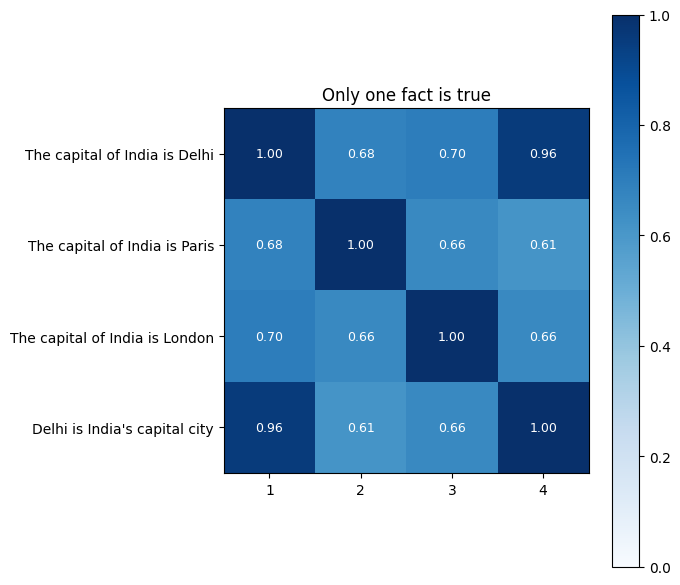

In [ ]:
s2 = ["The capital of India is Delhi", "The capital of India is Paris", "The capital of India is London",
      "Delhi is India's capital city"]
show_matrix(sim_matrix(s2), s2, "Only one fact is true")

In [ ]:
pairs = [("I love this movie", "I don't love this movie"),
         ("I like mango", "I don't like mango anymore"),
         ("The patient has diabetes", "The patient does not have diabetes"),
         ("I love this movie", "The film was wonderful")]
for a, b in pairs:
    x, y = model.encode([a, b])
    print(f"{cos(x, y):.3f}   {a!r}  vs  {b!r}")

0.760   'I love this movie'  vs  "I don't love this movie"
0.799   'I like mango'  vs  "I don't like mango anymore"
0.839   'The patient has diabetes'  vs  'The patient does not have diabetes'
0.591   'I love this movie'  vs  'The film was wonderful'


**Look for:** the false capitals score about as high as a true paraphrase, and opposite statements often score higher than a real paraphrase. Embeddings capture topic and form, not truth.

## 3. Inside an embedding

### Step 1: tokens

In [24]:
bert = AutoTokenizer.from_pretrained("bert-base-uncased")
for s in ["Using a Transformer network is simple", "tokenization", "unbelievably", "Bengaluru"]:
    print(f"{s!r:45} -> {bert.tokenize(s)}")

'Using a Transformer network is simple'       -> ['using', 'a', 'transform', '##er', 'network', 'is', 'simple']
'tokenization'                                -> ['token', '##ization']
'unbelievably'                                -> ['un', '##bel', '##ie', '##va', '##bly']
'Bengaluru'                                   -> ['bengal', '##uru']


### Tokenizer algorithms side by side

WordPiece (BERT), byte-level BPE (GPT-2) and Unigram via SentencePiece (XLM-R) on the same text. Matches the four algorithm slides.

In [25]:
algos = {"WordPiece (BERT)": "bert-base-uncased",
         "Byte-level BPE (GPT-2)": "gpt2",
         "Unigram / SentencePiece (XLM-R)": "xlm-roberta-base"}
samples = ["I like mango", "tokenization", "मुझे आम पसंद है", "ನನಗೆ ಮಾವಿನ ಹಣ್ಣು ಇಷ್ಟ"]
for name, path in algos.items():
    t = AutoTokenizer.from_pretrained(path)
    print(f"\n== {name}")
    for s in samples:
        toks = t.tokenize(s)
        print(f"  {len(toks):3}  {s!r:28} {toks}")
# GPT-2 shows Indic text as odd byte symbols: each character is several bytes
for ch in ["a", "é", "म", "ಮ"]:
    print(ch, len(ch.encode("utf-8")), "bytes in UTF-8")


== WordPiece (BERT)
    3  'I like mango'               ['i', 'like', 'mango']
    2  'tokenization'               ['token', '##ization']
    7  'मुझे आम पसंद है'            ['[UNK]', 'आ', '##म', 'प', '##स', '##द', 'ह']
    4  'ನನಗೆ ಮಾವಿನ ಹಣ್ಣು ಇಷ್ಟ'      ['[UNK]', '[UNK]', '[UNK]', '[UNK]']

== Byte-level BPE (GPT-2)
    3  'I like mango'               ['I', 'Ġlike', 'Ġmango']
    2  'tokenization'               ['token', 'ization']
   24  'मुझे आम पसंद है'            ['à¤', '®', 'à¥', 'ģ', 'à¤', 'Ŀ', 'à¥', 'ĩ', 'Ġà¤', 'Ĩ', 'à¤', '®', 'Ġà¤', 'ª', 'à¤', '¸', 'à¤', 'Ĥ', 'à¤', '¦', 'Ġà¤', '¹', 'à¥', 'Ī']
   56  'ನನಗೆ ಮಾವಿನ ಹಣ್ಣು ಇಷ್ಟ'      ['à', '²', '¨', 'à', '²', '¨', 'à', '²', 'Ĺ', 'à', '³', 'Ĩ', 'Ġ', 'à', '²', '®', 'à', '²¾', 'à', '²', 'µ', 'à', '²', '¿', 'à', '²', '¨', 'Ġ', 'à', '²', '¹', 'à', '²', '£', 'à', '³', 'į', 'à', '²', '£', 'à', '³', 'ģ', 'Ġ', 'à', '²', 'ĩ', 'à', '²', '·', 'à', '³', 'į', 'à', '²', 'Ł']

== Unigram / SentencePiece (XLM-R)
    4  'I like mango'              

### Step 2: context changes the vector

In [27]:
from transformers import AutoModel
import torch
bm = AutoModel.from_pretrained("bert-base-uncased")

def token_vector(sentence, word):
    enc = bert(sentence, return_tensors="pt")
    with torch.no_grad():
        out = bm(**enc).last_hidden_state[0]
    idx = enc.input_ids[0].tolist().index(bert.convert_tokens_to_ids(word))
    return out[idx].numpy()

river = token_vector("we sat on the river bank", "bank")
money = token_vector("I opened a bank account", "bank")
river2 = token_vector("the boat drifted to the bank of the river", "bank")
print(f"river bank vs bank account : {cos(river, money):.3f}")
print(f"river bank vs bank of river: {cos(river, river2):.3f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


river bank vs bank account : 0.332
river bank vs bank of river: 0.530


### Step 3: pooling into one sentence vector

In [28]:
# all-MiniLM-L6-v2 averages its token vectors (mean pooling) into one sentence vector.
print(model)   # look for the Pooling layer
v = model.encode("The sky is blue")
print("sentence vector shape:", v.shape)

SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'mean', 'include_prompt': True})
  (2): Normalize({})
)
sentence vector shape: (384,)


## 4. Other languages: token counts

The same sentence ("I like mango") in four languages, through tokenizers built differently. Use these numbers for the token-count slide.

In [29]:
lines = {"English": "I like mango",
         "Hindi": "मुझे आम पसंद है",
         "Kannada": "ನನಗೆ ಮಾವಿನ ಹಣ್ಣು ಇಷ್ಟ",
         "Sanskrit": "मह्यम् आम्रफलं रोचते"}
tokenizers = {"English BERT": "bert-base-uncased",
              "Multilingual BERT": "bert-base-multilingual-cased",
              "XLM-RoBERTa": "xlm-roberta-base",
              "MuRIL (Indian languages)": "google/muril-base-cased"}
counts = {}
for name, path in tokenizers.items():
    t = AutoTokenizer.from_pretrained(path)
    counts[name] = {}
    print(f"\n== {name}")
    for lang, text in lines.items():
        toks = t.tokenize(text)
        counts[name][lang] = len(toks)
        print(f"  {lang:9} {len(toks):3} tokens  {toks}")


== English BERT
  English     3 tokens  ['i', 'like', 'mango']
  Hindi       7 tokens  ['[UNK]', 'आ', '##म', 'प', '##स', '##द', 'ह']
  Kannada     4 tokens  ['[UNK]', '[UNK]', '[UNK]', '[UNK]']
  Sanskrit    9 tokens  ['म', '##ह', '##य', '##म', '[UNK]', 'र', '##ो', '##च', '##त']

== Multilingual BERT
  English     4 tokens  ['I', 'like', 'mang', '##o']
  Hindi       9 tokens  ['म', '##ु', '##झ', '##े', 'आम', 'प', '##स', '##ंद', 'है']
  Kannada    10 tokens  ['ನ', '##ನ', '##ಗೆ', 'ಮ', '##ಾವ', '##ಿನ', 'ಹ', '##ಣ್ಣು', 'ಇ', '##ಷ್ಟ']
  Sanskrit   13 tokens  ['म', '##ह', '##्य', '##म्', 'आम', '##्र', '##फ', '##ल', '##ं', 'र', '##ो', '##च', '##ते']

== XLM-RoBERTa
  English     4 tokens  ['▁I', '▁like', '▁man', 'go']
  Hindi       4 tokens  ['▁मुझे', '▁आम', '▁पसंद', '▁है']
  Kannada     7 tokens  ['▁ನನಗೆ', '▁ಮಾ', 'ವಿನ', '▁ಹ', 'ಣ್ಣ', 'ು', '▁ಇಷ್ಟ']
  Sanskrit   10 tokens  ['▁मह', '्य', 'म्', '▁आम', '्र', 'फल', 'ं', '▁रो', 'च', 'ते']

== MuRIL (Indian languages)
  English     3 tokens  ['I', 'lik

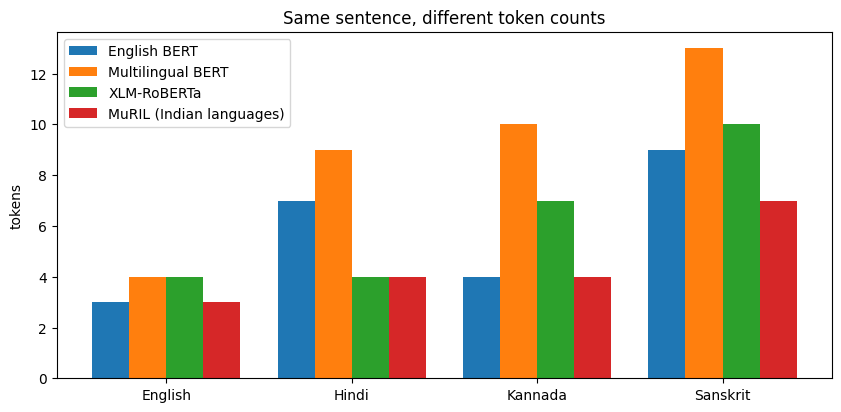

In [30]:
langs = list(lines)
x = np.arange(len(langs)); w = 0.2
plt.figure(figsize=(10, 4.5))
for i, (name, c) in enumerate(counts.items()):
    plt.bar(x + i * w, [c[l] for l in langs], w, label=name)
plt.xticks(x + 1.5 * w, langs); plt.ylabel("tokens"); plt.title("Same sentence, different token counts")
plt.legend(); plt.show()

In [31]:
# The counts on the token-count slide: OpenAI's GPT-4 and GPT-4o tokenizers
!pip install -q tiktoken
import tiktoken
for name in ["cl100k_base", "o200k_base"]:          # GPT-4, GPT-4o
    enc = tiktoken.get_encoding(name)
    print(name, {lang: len(enc.encode(text)) for lang, text in lines.items()})

cl100k_base {'English': 3, 'Hindi': 16, 'Kannada': 36, 'Sanskrit': 21}
o200k_base {'English': 3, 'Hindi': 5, 'Kannada': 10, 'Sanskrit': 10}


**Look for:** the English tokenizer may turn Indic text into unknown tokens (`[UNK]`) or many tiny pieces, because its vocabulary barely covers those scripts. Tokenizers trained on Indian languages need far fewer, more meaningful tokens.

## 5. The right model finds more

English documents, Hindi queries. Which model finds the right document?

In [32]:
docs = ["I like mango", "The sky is blue", "The train is running late", "Where is the library?",
        "My phone battery is dead", "It is raining heavily today", "She is reading a book",
        "The tea is very hot", "I am going to the market", "The doctor will see you now"]
hindi = ["मुझे आम पसंद है", "आसमान नीला है", "रेलगाड़ी देर से आ रही है", "पुस्तकालय कहाँ है?",
         "मेरे फ़ोन की बैटरी ख़त्म हो गई है", "आज तेज़ बारिश हो रही है", "वह किताब पढ़ रही है",
         "चाय बहुत गरम है", "मैं बाज़ार जा रहा हूँ", "डॉक्टर अब आपसे मिलेंगे"]

def top1_accuracy(m):
    D = m.encode(docs, normalize_embeddings=True)
    Q = m.encode(hindi, normalize_embeddings=True)
    return np.mean((Q @ D.T).argmax(axis=1) == np.arange(len(docs)))

multi = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
print(f"English-only model : {top1_accuracy(model):.0%} top-1 accuracy")
print(f"Multilingual model : {top1_accuracy(multi):.0%} top-1 accuracy")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

English-only model : 10% top-1 accuracy
Multilingual model : 100% top-1 accuracy


## 6. Teaser: data that isn't language

In [33]:
for s in ["192.168.1.1", "10.0.0.1", "172.16.8.201"]:
    print(f"{s:15} -> {bert.tokenize(s)}")
a = "src=192.168.1.14 dst=10.0.0.5 proto=TCP port=443 bytes=1200 duration=0.40"
b = "src=172.16.8.201 dst=8.8.8.8 proto=UDP port=53 bytes=980000 duration=212.70"
x, y = model.encode([a, b])
print(f"\ntwo very different records: cosine = {cos(x, y):.3f}")

192.168.1.1     -> ['192', '.', '168', '.', '1', '.', '1']
10.0.0.1        -> ['10', '.', '0', '.', '0', '.', '1']
172.16.8.201    -> ['172', '.', '16', '.', '8', '.', '201']

two very different records: cosine = 0.777


## 7. Index benchmark: Flat, IVF, HNSW, IVF-PQ

Synthetic clustered data (real embeddings are clustered). Exact brute force gives the answer key; then compare recall@10, latency, memory and build time. These numbers feed the "same data, four indexes" slide; rerun them on your machine.

In [34]:
d, n, nq, k = 128, 100_000, 500, 10
centers = rng.normal(size=(200, d)).astype("float32")
xb = (centers[rng.integers(0, 200, n)] + 0.35 * rng.normal(size=(n, d))).astype("float32")
xq = (centers[rng.integers(0, 200, nq)] + 0.35 * rng.normal(size=(nq, d))).astype("float32")

flat = faiss.IndexFlatL2(d); flat.add(xb)
t = time.perf_counter(); _, gt = flat.search(xq, k); flat_ms = (time.perf_counter() - t) / nq * 1000

def recall_at_k(found, truth):
    return np.mean([len(set(f) & set(t)) / len(t) for f, t in zip(found, truth)])
def mem_mb(index):
    return faiss.serialize_index(index).nbytes / 1e6
def evaluate(name, index, setting):
    t = time.perf_counter(); _, I = index.search(xq, k); ms = (time.perf_counter() - t) / nq * 1000
    return dict(index=name, setting=setting, recall=recall_at_k(I, gt), ms=ms, mb=mem_mb(index))

results = [dict(index="Flat", setting="exact", recall=1.0, ms=flat_ms, mb=mem_mb(flat))]
build = {}
t = time.perf_counter(); ivf = faiss.IndexIVFFlat(faiss.IndexFlatL2(d), d, 256); ivf.train(xb); ivf.add(xb); build["IVF"] = time.perf_counter() - t
for p in [1, 2, 4, 8, 16, 32]:
    ivf.nprobe = p; results.append(evaluate("IVF", ivf, f"nprobe={p}"))
t = time.perf_counter(); hnsw = faiss.IndexHNSWFlat(d, 32); hnsw.add(xb); build["HNSW"] = time.perf_counter() - t
for ef in [16, 32, 64, 128, 256]:
    hnsw.hnsw.efSearch = ef; results.append(evaluate("HNSW", hnsw, f"efSearch={ef}"))
t = time.perf_counter(); ivfpq = faiss.IndexIVFPQ(faiss.IndexFlatL2(d), d, 256, 16, 8); ivfpq.train(xb); ivfpq.add(xb); build["IVF-PQ"] = time.perf_counter() - t
for p in [1, 4, 16, 32]:
    ivfpq.nprobe = p; results.append(evaluate("IVF-PQ", ivfpq, f"nprobe={p}"))

print("build time (s):", {k: round(v, 1) for k, v in build.items()})
print(f"{'index':8} {'setting':14} {'recall@10':>9} {'ms/query':>9} {'MB':>8}")
for r in results:
    print(f"{r['index']:8} {r['setting']:14} {r['recall']:9.3f} {r['ms']:9.3f} {r['mb']:8.1f}")

build time (s): {'IVF': 2.5, 'HNSW': 15.9, 'IVF-PQ': 8.1}
index    setting        recall@10  ms/query       MB
Flat     exact              1.000     6.995     51.2
IVF      nprobe=1           0.914     0.050     52.1
IVF      nprobe=2           0.986     0.129     52.1
IVF      nprobe=4           1.000     0.275     52.1
IVF      nprobe=8           1.000     0.688     52.1
IVF      nprobe=16          1.000     1.201     52.1
IVF      nprobe=32          1.000     1.444     52.1
HNSW     efSearch=16        0.934     0.076     78.4
HNSW     efSearch=32        0.972     0.099     78.4
HNSW     efSearch=64        0.986     0.138     78.4
HNSW     efSearch=128       0.993     0.214     78.4
HNSW     efSearch=256       0.995     0.353     78.4
IVF-PQ   nprobe=1           0.289     0.037      2.7
IVF-PQ   nprobe=4           0.304     0.201      2.7
IVF-PQ   nprobe=16          0.304     0.565      2.7
IVF-PQ   nprobe=32          0.304     0.906      2.7


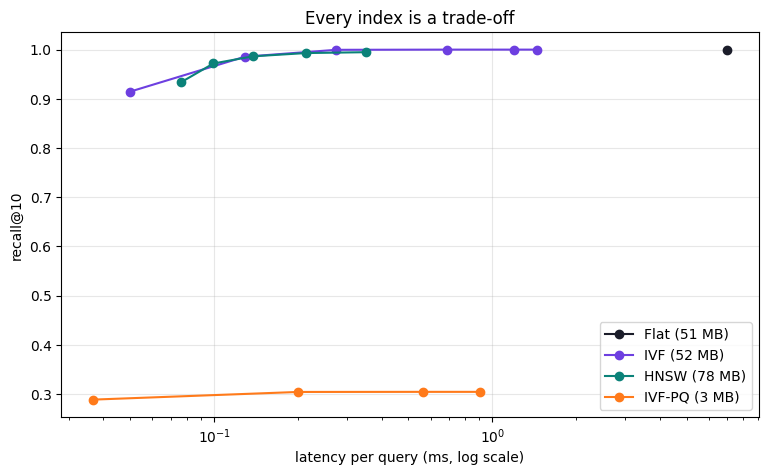

In [35]:
colors = {"Flat": "#1b1d2a", "IVF": "#6d3fe0", "HNSW": "#0b8279", "IVF-PQ": "#ff7a1a"}
plt.figure(figsize=(9, 5))
for name, c in colors.items():
    rs = [r for r in results if r["index"] == name]
    plt.plot([r["ms"] for r in rs], [r["recall"] for r in rs], "o-", color=c, label=f"{name} ({rs[0]['mb']:.0f} MB)")
plt.xscale("log"); plt.xlabel("latency per query (ms, log scale)"); plt.ylabel("recall@10")
plt.title("Every index is a trade-off"); plt.legend(); plt.grid(alpha=0.3); plt.show()

**Read the chart:** up and to the left is better. IVF at nprobe=1 is the "neighbour across the line" failure: true matches in skipped clusters are missed.

## 8. Fewer bits: int8 and binary

In [36]:
xb_n = xb / np.linalg.norm(xb, axis=1, keepdims=True); xq_n = xq / np.linalg.norm(xq, axis=1, keepdims=True)
fl = faiss.IndexFlatIP(d); fl.add(xb_n); _, gt_n = fl.search(xq_n, k)

sq = faiss.IndexScalarQuantizer(d, faiss.ScalarQuantizer.QT_8bit, faiss.METRIC_INNER_PRODUCT)
sq.train(xb_n); sq.add(xb_n); _, I_sq = sq.search(xq_n, k)

to_bits = lambda x: np.packbits((x > 0).astype(np.uint8), axis=1)
bi = faiss.IndexBinaryFlat(d); bi.add(to_bits(xb_n)); _, I_bin = bi.search(to_bits(xq_n), k)

# binary first pass, then rescore the top 100 at full precision
_, cand = bi.search(to_bits(xq_n), 100)
I_resc = np.array([c[np.argsort(-(xb_n[c] @ q))[:k]] for c, q in zip(cand, xq_n)])

for name, I, mb in [("float32", gt_n, xb_n.nbytes / 1e6), ("int8", I_sq, n * d / 1e6),
                    ("binary", I_bin, n * d / 8 / 1e6), ("binary + rescore", I_resc, n * d / 8 / 1e6)]:
    print(f"{name:17} recall@10 = {recall_at_k(I, gt_n):.3f}   vectors ≈ {mb:6.1f} MB")

float32           recall@10 = 1.000   vectors ≈   51.2 MB
int8              recall@10 = 0.916   vectors ≈   12.8 MB
binary            recall@10 = 0.099   vectors ≈    1.6 MB
binary + rescore  recall@10 = 0.491   vectors ≈    1.6 MB


## 9. Metrics: cosine, dot, Euclidean

In [37]:
normal = np.array([1200, 10, 0.4])     # bytes, packets, duration (toy)
big = normal * 1000                     # same proportions, 1000x the size
other = np.array([60, 40, 30.0])
for name, v in [("1000x the size", big), ("different shape", other)]:
    print(f"{name:16} cosine={cos(normal, v):.3f}  dot={np.dot(normal, v):,.0f}  euclidean={np.linalg.norm(normal - v):,.0f}")

1000x the size   cosine=1.000  dot=1,440,100,160  euclidean=1,198,842
different shape  cosine=0.773  dot=72,412  euclidean=1,141


## 10. Failure cases

### Failure 1: mixing embedding models

In [38]:
m_b = SentenceTransformer("sentence-transformers/paraphrase-MiniLM-L3-v2")   # also 384-d
corpus = ["cat", "dog", "kitten", "car", "bus", "train", "rice", "dosa"]
D_a = model.encode(corpus, normalize_embeddings=True)
for qm, label in [(model, "same model"), (m_b, "different model")]:
    q = qm.encode(["puppy"], normalize_embeddings=True)
    top = np.argsort(-(q @ D_a.T)[0])[:3]
    print(f"{label:16} -> {[corpus[i] for i in top]}")

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

same model       -> ['dog', 'kitten', 'cat']
different model  -> ['kitten', 'dog', 'cat']


Same vector length, no error, nonsense results. After a model change, re-embed everything.

### Failure 2: the neighbour across the line

See section 7: IVF with `nprobe=1` misses true neighbours that sit in clusters it skips.

### Failure 3: filtering after the search

In [39]:
years = rng.choice([2023, 2024, 2025, 2026], size=n, p=[0.4, 0.3, 0.2, 0.1])
_, I = hnsw.search(xq[:1], 10)
kept = [i for i in I[0] if years[i] == 2026]
print(f"asked for 10, filter year=2026 kept {len(kept)}")

asked for 10, filter year=2026 kept 0


### Failure 4: chunk size

In [40]:
pricing = "Our basic plan costs 499 rupees a month and the pro plan costs 999 rupees a month."
refunds = "Refunds are processed within seven working days after the request is approved."
big_chunk = pricing + " " + refunds
q = "How much does the pro plan cost?"
qv, pv, bv = model.encode([q, pricing, big_chunk])
print(f"query vs pricing chunk : {cos(qv, pv):.3f}")
print(f"query vs combined chunk: {cos(qv, bv):.3f}")

query vs pricing chunk : 0.646
query vs combined chunk: 0.647


### Failure 5: the longest vector wins

In [41]:
qv = np.array([1.0, 0.2]); relevant = np.array([0.9, 0.2]); off_topic = np.array([3.0, 6.0])
for name, v in [("relevant, short", relevant), ("off-topic, long", off_topic)]:
    print(f"{name:16} dot={np.dot(qv, v):.2f}  cosine={cos(qv, v):.2f}")

relevant, short  dot=0.94  cosine=1.00
off-topic, long  dot=4.20  cosine=0.61


Dot product picks the long off-topic vector; cosine picks the relevant one. Normalize, and match the index metric to the model.

## 11. Storage calculator

In [42]:
def storage_gb(n_vectors, dims, bytes_per_value=4):
    return n_vectors * dims * bytes_per_value / 1e9
for dims in [384, 768, 1536]:
    print(f"1M x {dims:4}-d: float32 {storage_gb(1e6, dims):.1f} GB | int8 {storage_gb(1e6, dims, 1):.2f} GB | binary {storage_gb(1e6, dims, 1/8):.3f} GB")

1M x  384-d: float32 1.5 GB | int8 0.38 GB | binary 0.048 GB
1M x  768-d: float32 3.1 GB | int8 0.77 GB | binary 0.096 GB
1M x 1536-d: float32 6.1 GB | int8 1.54 GB | binary 0.192 GB


## Try it yourself
1. Add your own sentence pairs to section 2. Can you find two that mean opposite things but score above 0.9?
2. Add another language (Tamil, Telugu, Malayalam) to section 4.
3. In section 7, change the cluster spread from `0.35` to `1.0`. What happens to IVF?
4. Before you pick anything for a project, write down your memory budget and latency target.